# EV Battery Degradation Prediction (Simplified)

**Goal:** predict battery State of Health (`SoH_Percent`) using regression.

This shorter notebook keeps the same core workflow: load data, inspect it, preprocess features, compare regression models, evaluate the best model, and save it. It uses only **two graphs**.

## 1. Import libraries

In [1]:
import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the CSV

Upload the CSV when prompted, or place it beside the notebook. If you have a ZIP containing the CSV, the notebook can read that too.

In [2]:
CSV_PATH = "ev_battery_degradation_v1.csv"
ZIP_PATH = "archive (1).zip"

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
elif os.path.exists(ZIP_PATH):
    with zipfile.ZipFile(ZIP_PATH) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df = pd.read_csv(f)
else:
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_name = next((n for n in uploaded if n.lower().endswith(".csv")), None)
        zip_name = next((n for n in uploaded if n.lower().endswith(".zip")), None)
        if csv_name:
            df = pd.read_csv(csv_name)
        elif zip_name:
            with zipfile.ZipFile(zip_name) as zf:
                csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
                with zf.open(csv_name) as f:
                    df = pd.read_csv(f)
        else:
            raise FileNotFoundError("Please upload a CSV or ZIP containing a CSV.")
    except ImportError:
        raise FileNotFoundError("Set CSV_PATH to your dataset file.")

print("Dataset shape:", df.shape)
display(df.head())
print("\\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing values"))

Dataset shape: (10000, 13)


,Vehicle_ID,Car_Model,Battery_Type,Battery_Capacity_kWh,Vehicle_Age_Months,Total_Charging_Cycles,Avg_Temperature_C,Fast_Charge_Ratio,Avg_Discharge_Rate_C,Driving_Style,Internal_Resistance_Ohm,SoH_Percent,Battery_Status
0,1fb46ae8,Tesla Model 3,NMC,75.0,41,390,21.5,0.51,2.22,Aggressive,0.0362,94.60,Healthy
1,b7ef35aa,Tesla Model 3,NMC,75.0,29,401,18.0,0.62,1.34,Aggressive,0.0333,95.68,Healthy
2,76cb49e0,Ford Mustang Mach-E,NMC,88.0,71,941,18.4,0.78,1.48,Conservative,0.0526,89.80,Healthy
3,456a7aef,Ford Mustang Mach-E,NMC,88.0,57,378,10.8,0.61,0.72,Moderate,0.0314,96.29,Healthy
4,bd758049,Tesla Model 3,NMC,75.0,58,239,30.3,0.89,1.48,Conservative,0.0297,96.75,Healthy


\nMissing values per column:


,Missing values
Vehicle_ID,0
Car_Model,0
Battery_Type,0
Battery_Capacity_kWh,0
Vehicle_Age_Months,0
Total_Charging_Cycles,0
Avg_Temperature_C,0
Fast_Charge_Ratio,0
Avg_Discharge_Rate_C,0
Driving_Style,0


## 3. Prepare features and target

The target is `SoH_Percent`. ID columns are not useful predictors. `Battery_Status` is excluded because it may be derived from battery health. The code uses the columns actually present in the CSV.

In [3]:
TARGET = "SoH_Percent"
if TARGET not in df.columns:
    raise ValueError(f"Target '{TARGET}' not found. Available columns: {df.columns.tolist()}")

df = df.drop_duplicates().copy()
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET])

exclude = [c for c in ["Vehicle_ID", "Vehicle id", "Vehicle_ID ", "Battery_Status"] if c in df.columns]
X = df.drop(columns=[TARGET] + exclude)
y = df[TARGET]

cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]

print("Rows used:", len(df))
print("Target:", TARGET)
print("Excluded columns:", exclude)
print("Number of input features:", X.shape[1])
print("Categorical features:", cat_cols)
print("Numerical features:", num_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

Rows used: 10000
Target: SoH_Percent
Excluded columns: ['Vehicle_ID', 'Battery_Status']
Number of input features: 10
Categorical features: ['Car_Model', 'Battery_Type', 'Driving_Style']
Numerical features: ['Battery_Capacity_kWh', 'Vehicle_Age_Months', 'Total_Charging_Cycles', 'Avg_Temperature_C', 'Fast_Charge_Ratio', 'Avg_Discharge_Rate_C', 'Internal_Resistance_Ohm']


C:\Users\Prem\AppData\Local\Temp\ipykernel_22584\3847689832.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()


## 4. Preprocess and train models

Missing values are filled automatically. Categorical values are one-hot encoded. Four regressors are compared, including a simple baseline.

In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, num_cols),
    ("cat", categorical_pipeline, cat_cols)
])

models = {
    "Dummy baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}

trained = {}
scores = []

for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    scores.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })
    trained[name] = pipe

results = pd.DataFrame(scores).sort_values("MAE").reset_index(drop=True)
display(results.round(3))
best_name = results.loc[0, "Model"]
best_model = trained[best_name]
print("Best model based on lowest MAE:", best_name)

,Model,MAE,RMSE,R2
0,Gradient Boosting,0.272,0.345,0.989
1,Random Forest,0.290,0.377,0.987
2,Linear Regression,0.310,0.413,0.984
3,Dummy baseline,2.567,3.261,-0.000


Best model based on lowest MAE: Gradient Boosting


## 5. Visualize model comparison and predictions

Only two graphs are included: model MAE comparison and actual-vs-predicted values for the best model.

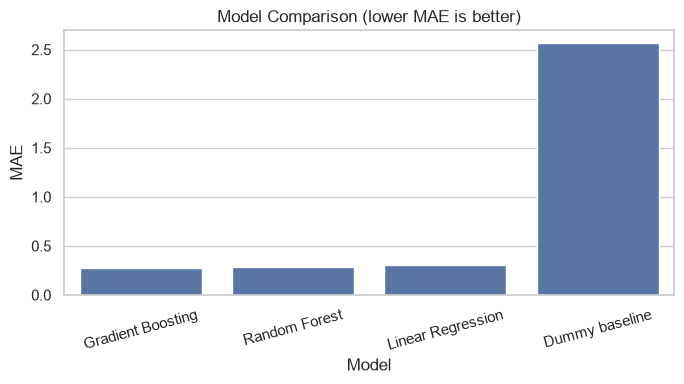

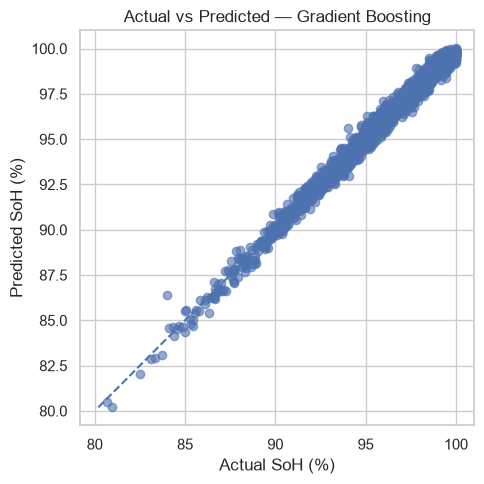

MAE:  0.272
RMSE: 0.345
R²:   0.989


In [5]:
# Graph 1: compare models by MAE
plt.figure(figsize=(7, 4))
sns.barplot(data=results, x="Model", y="MAE")
plt.title("Model Comparison (lower MAE is better)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Graph 2: actual vs predicted
pred = best_model.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.6)
low = min(y_test.min(), pred.min())
high = max(y_test.max(), pred.max())
plt.plot([low, high], [low, high], "--")
plt.xlabel("Actual SoH (%)")
plt.ylabel("Predicted SoH (%)")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()

print(f"MAE:  {mean_absolute_error(y_test, pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f}")
print(f"R²:   {r2_score(y_test, pred):.3f}")

## 6. Save the model

In [6]:
MODEL_FILE = "ev_battery_soh_model.joblib"
joblib.dump(best_model, MODEL_FILE)
print("Model saved as:", MODEL_FILE)

# Optional: download the model in Google Colab
# from google.colab import files
# files.download(MODEL_FILE)

Model saved as: ev_battery_soh_model.joblib


## 7. Predict for a new vehicle

The example uses typical values from the training data. Replace them with actual vehicle details for a meaningful prediction.

In [7]:
new_vehicle = {}
for col in X.columns:
    if col in num_cols:
        new_vehicle[col] = [X_train[col].median()]
    else:
        modes = X_train[col].mode(dropna=True)
        new_vehicle[col] = [modes.iloc[0] if len(modes) else "Unknown"]

new_data = pd.DataFrame(new_vehicle, columns=X.columns)
predicted_soh = best_model.predict(new_data)[0]
display(new_data)
print(f"Predicted battery State of Health: {predicted_soh:.2f}%")

,Car_Model,Battery_Type,Battery_Capacity_kWh,Vehicle_Age_Months,Total_Charging_Cycles,Avg_Temperature_C,Fast_Charge_Ratio,Avg_Discharge_Rate_C,Driving_Style,Internal_Resistance_Ohm
0,BYD Atto 3,NMC,72.6,48.0,400.0,25.0,0.49,1.49,Moderate,0.0287


Predicted battery State of Health: 96.72%
